In [1]:
import os
import sys

sys.path.append("..")

import critical_loads as cl
import geopandas as gpd
import matplotlib.pyplot as plt
import nivapy3 as nivapy
import numpy as np
import pandas as pd
import rasterio
import rasterio.plot
from mpl_toolkits.axes_grid1 import make_axes_locatable
from osgeo import gdal

gdal.UseExceptions()
plt.style.use("ggplot")

In [2]:
# Connect to PostGIS
eng = nivapy.da.connect_postgis()

Connection successful.


# Exceedance calculations: October 2026

# Exceedances of critical loads for water using bias-corrected EMEP data

`01_update_deposition.ipynb` reads the latest EMEP deposition data supplied for the GP review and adds it to the database. This notebook calculates exceedances for water as follows:

 1. Change factors for 2040 and 2050 are calculated from the EMEP data as (EMEP_2040 / EMEP_2015) and (EMEP_2040 / EMEP_2015).
    
 2. The factors are applied to the NILU data for 2012-2016 (new method; 0.1 degree grid) to estimate bias-corrected future deposition.

 3. The bias-corrected deposition data are used together with the "standard" critical load estimates (`BC0` etc.) to estimate exceedances for water (using SSWC and FAB).

## 1. Deposition

In [3]:
# Show series of interest
series_ids = [26, 68, 69, 70]
ser_grid = cl.view_dep_series(eng).query("series_id in @series_ids")
ser_grid

,series_id,name,short_name,grid,description
25,26,Middel 2012-2016,1216_old,blr,Fordelt til BLR av NILU 2017 (Wenche Aas; old ...
67,68,EMEP 2015 GP-rev-2026,emep2015GP2026,0_1deg,v7a EMEP scenarios. Delivered October 2026.
68,69,EMEP 2040 GP-rev-2026,emep2040GP2026,0_1deg,v7a EMEP scenarios. Delivered October 2026.
69,70,EMEP 2050 GP-rev-2026,emep2050GP2026,0_1deg,v7a EMEP scenarios. Delivered October 2026.


In [4]:
# Export rasters of interest in mg/m2/yr
cell_size = 120
unit = "mgpm2pyr"
pars = ["nitrogen", "sulphur"]

for par in pars:
    for series_id in series_ids:
        cl.create_deposition_raster(
            series_id,
            par,
            unit,
            cell_size,
            eng,
            ndv=-1,
        )

The code below applies the delta-change method. It's a little more complicated than strictly necessary, as each dataset is processed in blocks to keep memory consumption low. An alternative would be to simply sign-in on a more powerful machine, in which case the `block` loop below could be removed.

In [5]:
# NILU grid to use as baseline for bias correction
nilu_base_name = "1216_old"

base_dep_dir = r"/home/jovyan/shared/common/critical_loads/raster/deposition"
for par in pars:
    for year in [2040, 2050]:
        nilu_hist_path = os.path.join(
            base_dep_dir,
            nilu_base_name,
            f"{par[0]}dep_mgpm2pyr_{nilu_base_name}_120m.tif",
        )
        emep_hist_path = os.path.join(
            base_dep_dir,
            "emep2015GP2026",
            f"{par[0]}dep_mgpm2pyr_emep2015GP2026_120m.tif",
        )
        emep_fut_path = os.path.join(
            base_dep_dir,
            f"emep{year}GP2026",
            f"{par[0]}dep_mgpm2pyr_emep{year}GP2026_120m.tif",
        )

        nilu_hist_src = rasterio.open(nilu_hist_path)
        emep_hist_src = rasterio.open(emep_hist_path)
        emep_fut_src = rasterio.open(emep_fut_path)

        # Create output dataset
        out_dir = os.path.join(base_dep_dir, f"bcpred{year}")
        if not os.path.exists(out_dir):
            os.makedirs(out_dir)
        out_tif = os.path.join(out_dir, f"{par[0]}dep_mgpm2pyr_bcpred{year}_120m.tif")
        prof = nilu_hist_src.profile
        out_dst = rasterio.open(out_tif, "w", **prof)

        # Process in blocks to conserve memory
        for block_index, window in nilu_hist_src.block_windows(1):
            nilu_hist_block = nilu_hist_src.read(window=window).astype(float)
            emep_hist_block = emep_hist_src.read(window=window).astype(float)
            emep_fut_block = emep_fut_src.read(window=window).astype(float)

            nilu_hist_block[nilu_hist_block == -1] = np.nan
            emep_hist_block[emep_hist_block == -1] = np.nan
            emep_fut_block[emep_fut_block == -1] = np.nan

            # Apply delta-change method
            pred_block = nilu_hist_block * emep_fut_block / emep_hist_block

            # Set NaN to -1
            pred_block = np.nan_to_num(pred_block, nan=-1)

            out_dst.write(pred_block.astype(rasterio.int16), window=window)

        # Tidy up
        nilu_hist_src.close()
        emep_hist_src.close()
        emep_fut_src.close()
        out_dst.close()

## 2. Exceedances of critical loads for water

In [6]:
# Series IDs. Note that these are not 'real' series IDs in the db,
# but can be used here as an identifier here nevertheless
fut_series_dict = {"2040bc": "bcpred2040", "2050bc": "bcpred2050"}

# CL grids. We don't have CL grids for the future, so use the grids below
# to define critical loads for the future period
cl_grids = "1721_blrgrid"

cell_size = 120
base_path = r"/home/jovyan/shared/common/critical_loads/raster"

### 2.1. SSWC model

In [7]:
for series_id, short_name in fut_series_dict.items():
    dep_dir = os.path.join(base_path, "deposition", short_name)
    cl_dir = os.path.join(base_path, "water", cl_grids)
    ex_dir = os.path.join(base_path, "exceedance", short_name)
    if not os.path.exists(ex_dir):
        os.makedirs(ex_dir)

    ex_df = cl.calculate_water_exceedance_sswc(
        series_id,
        short_name,
        dep_dir,
        cl_dir,
        ex_dir,
        cell_size=120,
        bc0="BC0",
        neg_to_zero=True,
    )

    print(f"\nSSWC exceedance for {short_name}:")
    display(ex_df)
    print("\n\n")

Exceedance grid saved to:
    /home/jovyan/shared/common/critical_loads/raster/exceedance/bcpred2040/sswc_ex_meqpm2pyr_bcpred2040_120m.tif

SSWC exceedance for bcpred2040:


,series_id,medium,total_area_km2,exceeded_area_km2,exceeded_area_pct
0,2040bc,water_sswc,320584,14561,5





Exceedance grid saved to:
    /home/jovyan/shared/common/critical_loads/raster/exceedance/bcpred2050/sswc_ex_meqpm2pyr_bcpred2050_120m.tif

SSWC exceedance for bcpred2050:


,series_id,medium,total_area_km2,exceeded_area_km2,exceeded_area_pct
0,2050bc,water_sswc,320584,14440,5


### 2.2. FAB model

In [8]:
# Read CL arrays
array_dict = {}
for par in [
    "clminn_meqpm2pyr",
    "clmaxnoaa_meqpm2pyr",
    "clmins_meqpm2pyr",
    "clmaxsoaa_meqpm2pyr",
]:
    # Read critical loads grids
    tif_path = os.path.join(base_path, "water", cl_grids, f"{par}_{cell_size}m.tif")
    data, ndv, epsg, extent = nivapy.spatial.read_raster(tif_path)

    # Set NDV
    data[data == ndv] = np.nan

    # Add to dict
    array_dict[par] = data

# Read dep arrays
for par in ["ndep_mgpm2pyr", "sdep_mgpm2pyr"]:
    for series_id, short_name in fut_series_dict.items():
        # Read tif
        tif_path = os.path.join(
            base_path, "deposition", short_name, f"{par}_{short_name}_{cell_size}m.tif"
        )
        data, ndv, epsg, extent = nivapy.spatial.read_raster(tif_path)
        data = data.astype(np.float32)

        # Set NDV
        data[data == ndv] = np.nan

        # Add to dict
        array_dict[(short_name, par)] = data

In [9]:
%%time

# Snap tiff
snap_tif = (
    f"/home/jovyan/shared/common/critical_loads/raster/blr_land_mask_{cell_size}m.tif"
)

# Extract arrays from dict
cln_min = array_dict["clminn_meqpm2pyr"]
cln_max = array_dict["clmaxnoaa_meqpm2pyr"]
cls_min = array_dict["clmins_meqpm2pyr"]
cls_max = array_dict["clmaxsoaa_meqpm2pyr"]

for series_id, short_name in fut_series_dict.items():
    ex_dir = os.path.join(base_path, "exceedance", short_name)
    if not os.path.exists(ex_dir):
        os.makedirs(ex_dir)

    dep_n = array_dict[(short_name, "ndep_mgpm2pyr")] / 14  # Convert to meq
    dep_s = array_dict[(short_name, "sdep_mgpm2pyr")] * 2 / 32.06  # Convert to meq

    # Estimate exceedances
    ex_n, ex_s, reg_id = cl.vectorised_exceed_ns_icpm(
        cln_min, cln_max, cls_min, cls_max, dep_n, dep_s
    )

    # Get exceeded area
    ex = ex_n + ex_s
    ex_area = np.count_nonzero(ex > 0) * cell_size * cell_size / 1.0e6
    nor_area = np.count_nonzero(~np.isnan(dep_s)) * cell_size * cell_size / 1.0e6
    ex_pct = 100 * ex_area / nor_area

    # Build df and tidy
    ex_df = pd.DataFrame(
        {
            "exceeded_area_km2": ex_area,
            "total_area_km2": nor_area,
            "exceeded_area_pct": ex_pct,
        },
        index=[0],
    )

    ex_df = ex_df.round(0).astype(int)
    ex_df["series_id"] = series_id
    ex_df["medium"] = "water_fab"

    ex_df = ex_df[
        [
            "series_id",
            "medium",
            "total_area_km2",
            "exceeded_area_km2",
            "exceeded_area_pct",
        ]
    ]

    # Save output grids
    n_tif = os.path.join(ex_dir, f"fab_exn_meqpm2pyr_{short_name}_{cell_size}m.tif")
    cl.write_geotiff(ex_n, n_tif, snap_tif, -1, gdal.GDT_Float32)

    s_tif = os.path.join(ex_dir, f"fab_exs_meqpm2pyr_{short_name}_{cell_size}m.tif")
    cl.write_geotiff(ex_s, s_tif, snap_tif, -1, gdal.GDT_Float32)

    ns_tif = os.path.join(ex_dir, f"fab_exns_meqpm2pyr_{short_name}_{cell_size}m.tif")
    cl.write_geotiff(ex_n + ex_s, ns_tif, snap_tif, -1, gdal.GDT_Float32)

    reg_tif = os.path.join(ex_dir, f"fab_ex_reg_id_{short_name}_{cell_size}m.tif")
    cl.write_geotiff(reg_id, reg_tif, snap_tif, -1, gdal.GDT_Float32)

    print(f"\nFAB exceedance for {short_name}:")
    display(ex_df)
    print("\n\n")


FAB exceedance for bcpred2040:


,series_id,medium,total_area_km2,exceeded_area_km2,exceeded_area_pct
0,2040bc,water_fab,320584,37940,12






FAB exceedance for bcpred2050:


,series_id,medium,total_area_km2,exceeded_area_km2,exceeded_area_pct
0,2050bc,water_fab,320584,35766,11





CPU times: user 45.3 s, sys: 15 s, total: 1min
Wall time: 1min 1s


## 3. Maps

### 3.1. Deposition

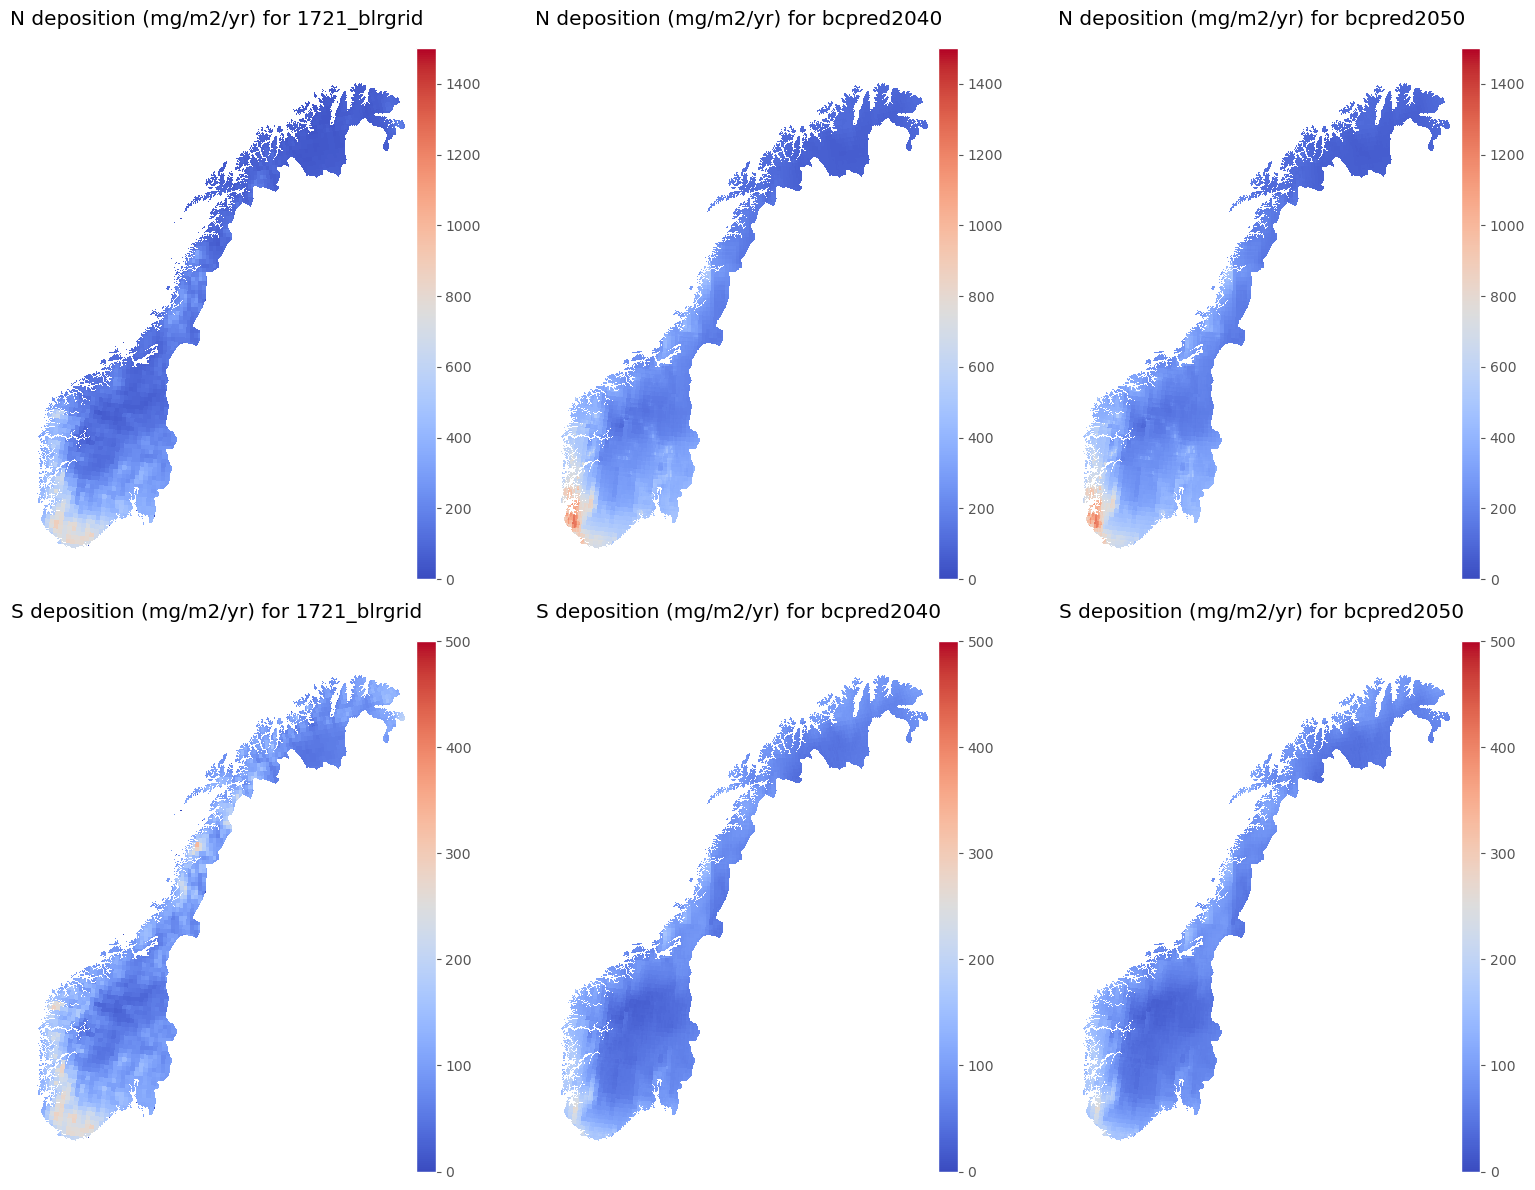

In [10]:
pars = ["n", "s"]
names = [cl_grids, "bcpred2040", "bcpred2050"]
vmax_dict = {
    "n": 1500,
    "s": 500,
}

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 12))

for row_idx, par in enumerate(pars):
    for col_idx, name in enumerate(names):
        ras_path = f"/home/jovyan/shared/common/critical_loads/raster/deposition/{name}/{par}dep_mgpm2pyr_{name}_{cell_size}m.tif"
        with rasterio.open(ras_path) as src:
            divider = make_axes_locatable(axes[row_idx, col_idx])
            cax = divider.append_axes("right", size="5%", pad=0.05)

            im = rasterio.plot.show(
                src,
                ax=axes[row_idx, col_idx],
                cmap="coolwarm",
                interpolation="none",
                vmin=0,
                vmax=vmax_dict[par],
            )

            fig.colorbar(im.images[0], cax=cax)
            axes[row_idx, col_idx].set_title(
                f"{par.upper()} deposition (mg/m2/yr) for {name}"
            )
            axes[row_idx, col_idx].axis("off")

plt.tight_layout()

### 3.2. Exceedance

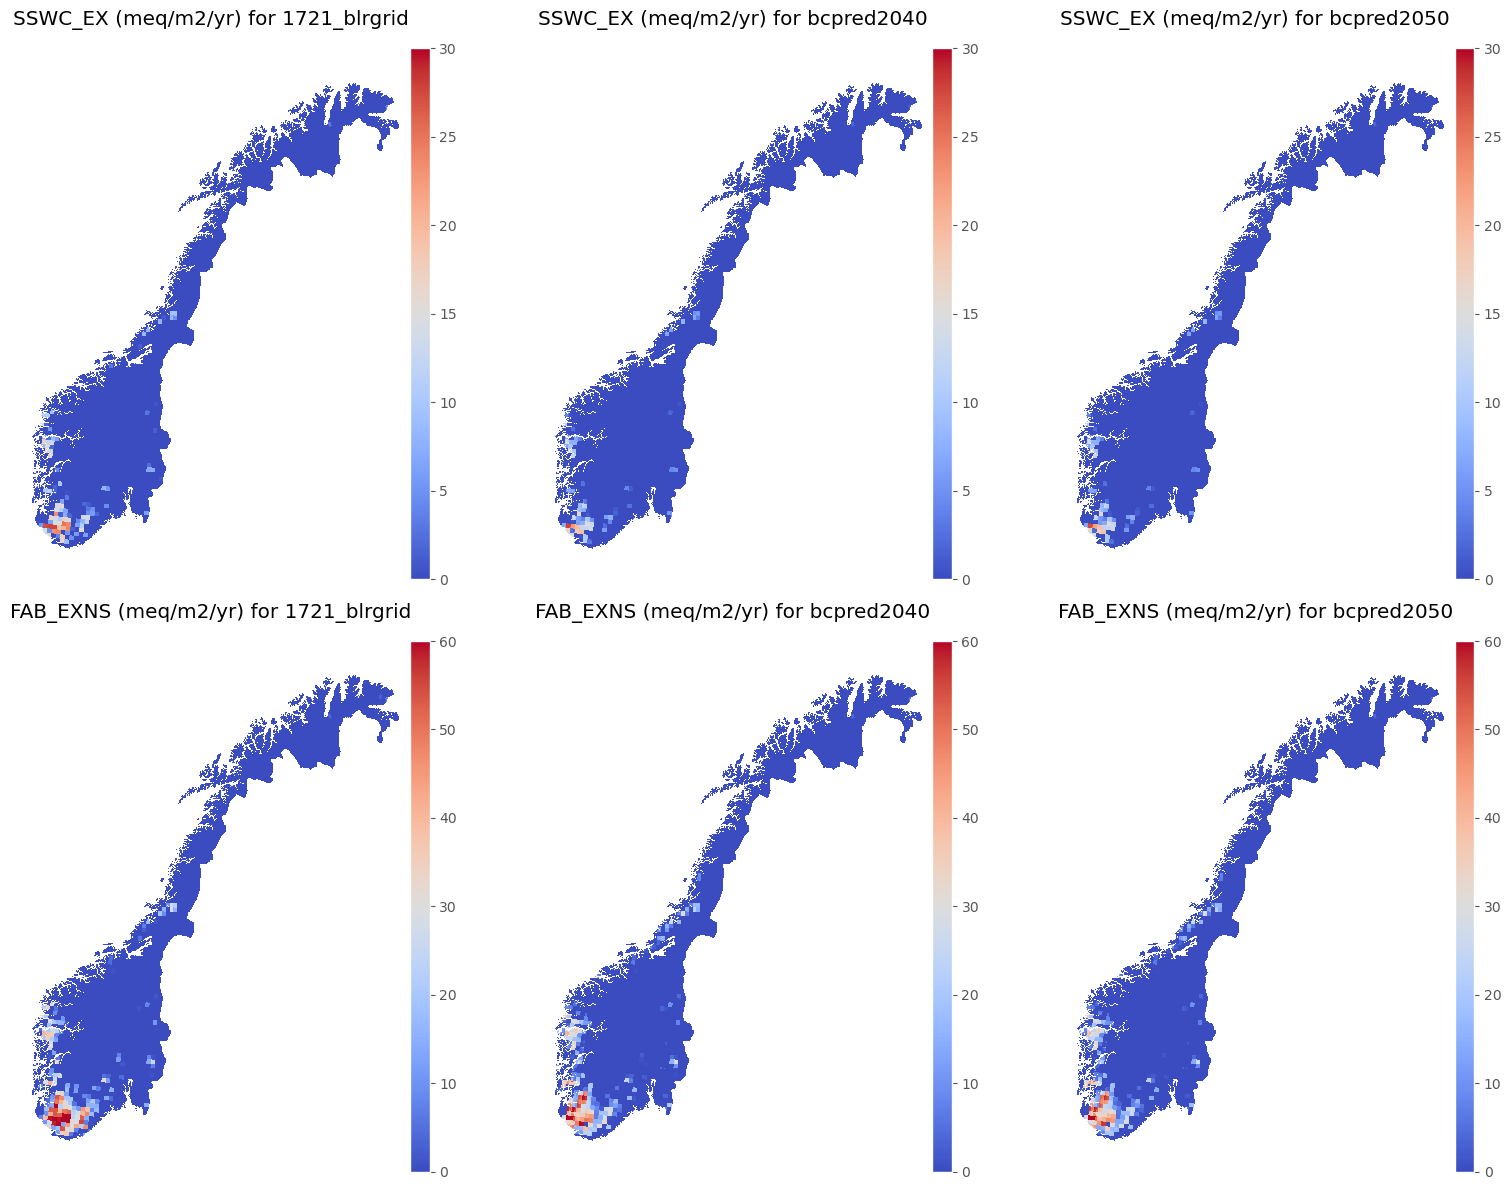

In [11]:
models = ["sswc_ex", "fab_exns"]
names = [cl_grids, "bcpred2040", "bcpred2050"]
vmax_dict = {
    "sswc_ex": 30,
    "fab_exns": 60,
}

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 12))

for row_idx, model in enumerate(models):
    for col_idx, name in enumerate(names):
        ras_path = f"/home/jovyan/shared/common/critical_loads/raster/exceedance/{name}/{model}_meqpm2pyr_{name}_{cell_size}m.tif"
        with rasterio.open(ras_path) as src:
            divider = make_axes_locatable(axes[row_idx, col_idx])
            cax = divider.append_axes("right", size="5%", pad=0.05)

            im = rasterio.plot.show(
                src,
                ax=axes[row_idx, col_idx],
                cmap="coolwarm",
                interpolation="none",
                vmin=0,
                vmax=vmax_dict[model],
            )

            fig.colorbar(im.images[0], cax=cax)
            axes[row_idx, col_idx].set_title(f"{model.upper()} (meq/m2/yr) for {name}")
            axes[row_idx, col_idx].axis("off")

plt.tight_layout()